# Modelos Matemáticos y Estadísticos Clásicos
## Diplomado en Data Science 2026

---

## Taller 2


**Integrantes**:

-
-
-


## Caso: Empresa de comercio electrónico

Formas parte del equipo de Data Science de una empresa de comercio electrónico. Un analista del equipo ha estado trabajando en distintos problemas relacionados con operación, tiempos de entrega, riesgo de atraso y planificación de demanda.

Tu tarea **no consiste solamente en ejecutar modelos**. Durante esta evaluación deberás revisar el trabajo del analista, decidir si sus conclusiones son correctas, proponer mejoras cuando corresponda y justificar tus decisiones.

### Objetivos evaluados

Se espera que seas capaz de:

- identificar qué herramienta estadística es apropiada para una pregunta;
- distinguir entre una asociación descriptiva, evidencia estadística y causalidad;
- interpretar correctamente resultados y métricas;
- detectar cuándo una conclusión **sí** está respaldada por los datos y cuándo **no**;
- comparar modelos y justificar cuál utilizarías.

### Importante

- El código de preparación de datos ya está entregado y **no forma parte de la evaluación**.
- Puedes agregar las celdas de código o texto que estimes necesarias.
- Toda conclusión debe estar respaldada por resultados reproducibles en el notebook.
- No se evaluará la cantidad de código, sino la calidad del análisis.

---

#  Preparación de datos

El siguiente código construye una tabla analítica a nivel de pedido a partir de cuatro tablas de origen.

**No es necesario modificar esta sección.**


In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
import statsmodels.formula.api as smf

from scipy import stats
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    roc_auc_score,
    mean_absolute_error,
    root_mean_squared_error
)
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

URL_CUSTOMERS = "https://docs.google.com/spreadsheets/d/13l1up9hqmT8a3z1fj7283gEttstJ8tVFHpzxvwHpp4E/export?format=csv"
URL_ORDER_ITEMS = "https://docs.google.com/spreadsheets/d/1QkCG0Mt4GugaG7pRxnnafE3GulXoqUrkdo2sRFlfpCY/export?format=csv"
URL_ORDERS = "https://docs.google.com/spreadsheets/d/17_OkQhApsLwNoXpb8-63cVQ_zwu5uiQXiYZnpWBeEz8/export?format=csv"
URL_PRODUCTS = "https://docs.google.com/spreadsheets/d/1pN4sFbqEaZVuCQpkkDo-IZB7EgqMOyGUMfoZTbRaOo0/export?format=csv"

customers = pd.read_csv(URL_CUSTOMERS)
order_items = pd.read_csv(URL_ORDER_ITEMS)
orders = pd.read_csv(URL_ORDERS)
products = pd.read_csv(URL_PRODUCTS)

print("customers:", customers.shape)
print("order_items:", order_items.shape)
print("orders:", orders.shape)
print("products:", products.shape)


customers: (15150, 5)
order_items: (16767, 7)
orders: (15000, 8)
products: (9208, 9)


In [17]:
for col in [
    "order_item_id",
    "price",
    "freight_value"
]:
    if col in order_items.columns:
        order_items[col] = pd.to_numeric(
            order_items[col],
            errors="coerce"
        )

for col in [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]:
    if col in products.columns:
        products[col] = pd.to_numeric(
            products[col],
            errors="coerce"
        )


# Fechas
date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_cols:
    if col in orders.columns:
        orders[col] = pd.to_datetime(
            orders[col],
            errors="coerce",
            format="mixed"
        )

# Variables geométricas de productos
for col in [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]:
    if col in products.columns:
        products[col] = pd.to_numeric(products[col], errors="coerce")

if all(c in products.columns for c in ["product_length_cm", "product_height_cm", "product_width_cm"]):
    products["product_volume_cm3"] = (
        products["product_length_cm"]
        * products["product_height_cm"]
        * products["product_width_cm"]
    )

# Enriquecer ítems con atributos de producto
items_prod = order_items.merge(
    products[
        [c for c in [
            "product_id",
            "product_category_name",
            "product_weight_g",
            "product_volume_cm3"
        ] if c in products.columns]
    ],
    on="product_id",
    how="left"
)

# Agregación a nivel de pedido
agg_dict = {
    "n_items": ("order_item_id", "count"),
    "total_price": ("price", "sum"),
    "total_freight": ("freight_value", "sum"),
    "avg_item_price": ("price", "mean"),
    "n_products": ("product_id", "nunique"),
}

if "product_category_name" in items_prod.columns:
    agg_dict["n_categories"] = ("product_category_name", "nunique")
if "product_weight_g" in items_prod.columns:
    agg_dict["total_weight_g"] = ("product_weight_g", "sum")
if "product_volume_cm3" in items_prod.columns:
    agg_dict["total_volume_cm3"] = ("product_volume_cm3", "sum")

order_agg = (
    items_prod
    .groupby("order_id")
    .agg(**agg_dict)
    .reset_index()
)

# Tabla analítica
df = (
    orders
    .merge(customers, on="customer_id", how="left")
    .merge(order_agg, on="order_id", how="left")
)

# Variables derivadas
df["purchase_date"] = df["order_purchase_timestamp"].dt.floor("D")
df["purchase_weekday"] = df["order_purchase_timestamp"].dt.day_name()
df["purchase_month"] = df["order_purchase_timestamp"].dt.to_period("M").astype(str)
df["is_weekend_purchase"] = df["order_purchase_timestamp"].dt.dayofweek.ge(5).astype(int)

df["delivery_days"] = (
    df["order_delivered_customer_date"] - df["order_purchase_timestamp"]
).dt.total_seconds() / 86400

df["delay_days"] = (
    df["order_delivered_customer_date"] - df["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

df["days_to_carrier"] = (
    df["order_delivered_carrier_date"]
    - df["order_purchase_timestamp"]
).dt.total_seconds() / 86400


df["remaining_days"] = (
    df["order_estimated_delivery_date"]
    - df["order_delivered_carrier_date"]
).dt.total_seconds() / 86400

df["approval_hours"] = (
    df["order_approved_at"]
    - df["order_purchase_timestamp"]
).dt.total_seconds() / 3600


df["late_delivery"] = np.where(
    df["order_delivered_customer_date"].notna()
    & df["order_estimated_delivery_date"].notna(),
    (df["delay_days"] > 0).astype(int),
    np.nan
)

df["freight_ratio"] = df["total_freight"] / df["total_price"].replace(0, np.nan)

# Solo pedidos entregados para análisis de tiempos
delivered = df[
    (df["order_status"] == "delivered")
    & df["delivery_days"].notna()
].copy()

print("Tabla analítica:", df.shape)
print("Pedidos entregados:", delivered.shape)

display(delivered.head())


Tabla analítica: (15150, 31)
Pedidos entregados: (14688, 31)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,n_items,total_price,total_freight,avg_item_price,n_products,n_categories,total_weight_g,total_volume_cm3,purchase_date,purchase_weekday,purchase_month,is_weekend_purchase,delivery_days,delay_days,days_to_carrier,remaining_days,approval_hours,late_delivery,freight_ratio
0,3b14820d642ea72e95df3289b6539c1c,4248fddd68e3375c24e743290ce2d9fa,delivered,2018-04-02 13:01:06,2018-04-02 13:10:21,2018-04-04 23:42:34,2018-04-12 17:12:13,2018-04-23,a79c62e50e66e1036ba2cb2e5e00aff3,37190,tres pontas,MG,1.000,75.900,19.500,75.900,1.000,1.000,700.000,"6,912.000",2018-04-02,Monday,2018-04,0,10.174,-10.283,2.445,18.012,0.154,0.000,0.257
1,8a795486f112df15565463862960aa40,e093120ffd5c259e2decb4ff5266f0dd,delivered,2018-05-20 20:28:32,2018-05-22 09:36:09,2018-05-22 15:48:00,2018-06-01 11:50:31,2018-05-29,81ec41f3b0c51a9df15c5957140686fa,13084,campinas,SP,1.000,95.900,11.300,95.900,1.000,1.000,"1,400.000","27,000.000",2018-05-20,Sunday,2018-05,1,11.640,3.493,1.805,6.342,37.127,1.000,0.118
2,7aa2471c1e8d0cd89eec9459fde59414,0eb400f3e6d2f08e70d2ab5af9c203f4,delivered,2017-09-18 19:09:52,2017-09-20 02:10:42,2017-09-21 19:37:10,2017-09-27 19:09:10,2017-10-04,c64b0bf5855e1d6ba223d649298c2915,36889,muriae,MG,1.000,81.000,42.710,81.000,1.000,1.000,"18,100.000","4,332.000",2017-09-18,Monday,2017-09,0,9.000,-6.202,3.019,12.183,31.014,0.000,0.527
3,95cf53396116b5dd518b5ba1c11a0bb5,3b2e666d92ce663a2f35ba3a6bb5df6a,delivered,2017-04-21 19:31:13,2017-04-21 19:45:10,2017-04-25 13:08:20,2017-05-04 16:46:54,2017-05-19,4113a7e912e87f632986e0562da140c7,74075,goiania,GO,1.000,59.000,17.840,59.000,1.000,1.000,275.000,"1,936.000",2017-04-21,Friday,2017-04,0,12.886,-14.301,3.734,23.453,0.233,0.000,0.302
4,6c5eb0920626d3ff5588d03d6f2d4936,1b83beaaa59c8cdfe738f7ead2517da8,delivered,2018-03-15 15:22:28,2018-03-17 03:08:57,2018-03-19 21:14:58,2018-05-03 11:29:52,2018-04-30,d69a93bce76b26886f72125e60b01cec,69040,manaus,AM,1.000,69.900,57.040,69.900,1.000,1.000,"1,200.000","21,000.000",2018-03-15,Thursday,2018-03,0,48.838,3.479,4.245,41.115,35.775,1.000,0.816


### Diccionario resumido de la tabla analítica

| Variable | Descripción |
|---|---|
| `order_id` | Identificador del pedido |
| `customer_state` | Estado/región del cliente |
| `purchase_date` | Fecha de compra |
| `purchase_weekday` | Día de la semana de compra |
| `is_weekend_purchase` | 1 si la compra se realizó sábado o domingo |
| `n_items` | Número de ítems del pedido |
| `n_products` | Número de productos distintos |
| `n_categories` | Número de categorías distintas, si está disponible |
| `total_price` | Valor total de los productos |
| `total_freight` | Valor total del despacho |
| `avg_item_price` | Precio promedio de los ítems |
| `total_weight_g` | Peso total aproximado de los productos |
| `total_volume_cm3` | Volumen total aproximado |
| `delivery_days` | Días transcurridos desde compra hasta entrega |
| `delay_days` | Días de diferencia respecto de la fecha comprometida |
| `days_to_carrier` | Número de días transcurridos desde que se realiza la compra hasta que el pedido es entregado al transportista. |
| `remaining_days` | Número de días disponibles entre la entrega del pedido al transportista y la fecha estimada de entrega al cliente. |
| `approval_hours` | Número de horas transcurridas desde que se realiza la compra hasta que el pedido es aprobado. |
| `late_delivery` | 1 si el pedido llegó después de la fecha comprometida |
| `freight_ratio` | Costo de despacho dividido por valor de productos |

---




## Primer bloque (20 puntos)

El analista preparó la siguiente tabla cruzada entre **tamaño del pedido** y **atraso**.

Primero creó dos grupos:

- `1_item`: pedidos con un solo ítem;
- `2_o_mas`: pedidos con dos o más ítems.

In [18]:
analisis_1 = delivered[
    delivered["late_delivery"].notna()
    & delivered["n_items"].notna()
].copy()

analisis_1["grupo_items"] = np.where(
    analisis_1["n_items"] == 1,
    "1_item",
    "2_o_mas"
)

tabla = pd.crosstab(
    analisis_1["grupo_items"],
    analisis_1["late_delivery"]
)

tabla


late_delivery,0.000,1.000
grupo_items,,
1_item,12054,1080
2_o_mas,1309,96


El analista luego calculó dos tablas:



In [19]:
# Tabla A
tabla_fila = pd.crosstab(
    analisis_1["grupo_items"],
    analisis_1["late_delivery"],
    normalize="index"
)

tabla_fila


late_delivery,0.000,1.000
grupo_items,,
1_item,0.918,0.082
2_o_mas,0.932,0.068


In [20]:
# Tabla B
tabla_columna = pd.crosstab(
    analisis_1["grupo_items"],
    analisis_1["late_delivery"],
    normalize="columns"
)

tabla_columna


late_delivery,0.000,1.000
grupo_items,,
1_item,0.902,0.918
2_o_mas,0.098,0.082



El analista afirma:

> "El analista observa que en la Tabla B el valor asociado a 1_item y late_delivery=1 es 0,918 y concluye que “los pedidos de un ítem tienen 91,8% de probabilidad de atraso”. ¿Es correcta esta interpretación?"


1. Explique qué representa el valor 0,082 de la Tabla A.  

2. Explique qué representa el valor 0,918 de la Tabla B.

3. ¿Cuál de las dos tablas permite comparar la probabilidad de atraso entre
pedidos de 1 ítem y de 2 o más ítems?

4. ¿Los resultados descriptivos apoyan la hipótesis del analista?

5. Evalúe si la diferencia observada es solo una cuestión de la muestra. Considere y explicite los supuestos/límites necesarios.
SI ES SIGNIFICATIVAMENTE DISTINTO O ES AZAR. PUEDE HABER UN ANÁLISIS ESTADíSTICO. Cálculo de probabilidades - Teoría Chi cuadrado de independencia
Calcula probabilidades condicionales al agrupar las tablas, todas sus conclusiones son en base a eso.


6. ¿Puede concluir que cambiar el número de ítems de un pedido modifica causalmente su probabilidad de atraso? Explique.

### Tu análisis


In [21]:
# Escribe aquí el código que necesites




**Respuesta e interpretación:**

Escribe aquí tu conclusión.


---

# Segundo Bloque (30 puntos)

El equipo está tratando de entender qué determina el costo de despacho de un pedido.

El analista propone dos modelos.

### Modelo A

Utiliza solamente una variable:


In [22]:
freight_data = delivered[
    delivered["total_freight"].notna()
    & delivered["total_weight_g"].notna()
    & delivered["total_volume_cm3"].notna()
    & delivered["total_price"].notna()
].copy()

modelo_A = smf.ols(
    "total_freight ~ total_volume_cm3",
    data=freight_data
).fit()

print(modelo_A.summary())


                            OLS Regression Results                            
Dep. Variable:          total_freight   R-squared:                       0.410
Model:                            OLS   Adj. R-squared:                  0.410
Method:                 Least Squares   F-statistic:                 1.008e+04
Date:                Tue, 18 Aug 2026   Prob (F-statistic):               0.00
Time:                        23:16:56   Log-Likelihood:                -60952.
No. Observations:               14539   AIC:                         1.219e+05
Df Residuals:                   14537   BIC:                         1.219e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           15.0518      0.154  

### Modelo B

Se consideró agregar 3 más!

In [23]:
modelo_B = smf.ols(
    """
    total_freight
    ~ total_price
    + total_weight_g
    + total_volume_cm3
    + n_items
    """,
    data=freight_data
).fit()

print(modelo_B.summary())


                            OLS Regression Results                            
Dep. Variable:          total_freight   R-squared:                       0.581
Model:                            OLS   Adj. R-squared:                  0.581
Method:                 Least Squares   F-statistic:                     5033.
Date:                Tue, 18 Aug 2026   Prob (F-statistic):               0.00
Time:                        23:16:56   Log-Likelihood:                -58463.
No. Observations:               14539   AIC:                         1.169e+05
Df Residuals:                   14534   BIC:                         1.170e+05
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            0.6562      0.271  

El analista concluye:

> “El Modelo B es necesariamente mejor porque tiene más variables y un R² mayor.”

Tu tarea es **evaluar críticamente su trabajo**.

Debes:

1. explicar si estás de acuerdo o no con la afirmación;
2. comparar los modelos utilizando criterios estadísticos que consideres pertinentes;
3. interpretar al menos **dos coeficientes** del Modelo B;
4. revisar gráficamente los supuestos/diagnósticos que consideres relevantes;
5. proponer y ajustar un **Modelo C** que consideres mejor especificado. Puedes incorporar variables disponibles en `freight_data`, transformar variables o eliminar variables;
6. recomendar finalmente A, B o C y justificar tu elección.

### Tu análisis


In [24]:
# Escribe aquí tu Modelo C y los análisis necesarios



**Recomendación final:**

Escribe aquí tu conclusión.


---

# Tercer Bloque (30 puntos)

El objetivo ahora es distinto:

> Al momento de procesar un pedido, queremos estimar el riesgo de que llegue después de la fecha comprometida.

El analista ajustó inicialmente el siguiente modelo:


In [25]:
logit_data = delivered[
    delivered["late_delivery"].notna()
    & delivered["total_price"].notna()
    & delivered["total_freight"].notna()
    & delivered["n_items"].notna()
    & delivered["n_categories"].notna()
    & delivered["days_to_carrier"].notna()
    & delivered["remaining_days"].notna()
    & delivered["approval_hours"].notna()
].copy()

modelo_riesgo_1 = smf.logit(
    """
    late_delivery
    ~ total_price
    + total_freight
    + n_items
    + n_categories
    + days_to_carrier
    + remaining_days
    + approval_hours
    + C(is_weekend_purchase)
    """,
    data=logit_data
).fit()

print(modelo_riesgo_1.summary())


Optimization terminated successfully.
         Current function value: 0.258033
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:          late_delivery   No. Observations:                14538
Model:                          Logit   Df Residuals:                    14529
Method:                           MLE   Df Model:                            8
Date:                Tue, 18 Aug 2026   Pseudo R-squ.:                 0.08154
Time:                        23:16:57   Log-Likelihood:                -3751.3
converged:                       True   LL-Null:                       -4084.3
Covariance Type:            nonrobust   LLR p-value:                1.429e-138
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept                      -1.2893      0.220     -5.857      0.000   

              precision    recall  f1-score   support

           0       0.92      1.00      0.96     13362
           1       0.74      0.06      0.11      1176

    accuracy                           0.92     14538
   macro avg       0.83      0.53      0.54     14538
weighted avg       0.91      0.92      0.89     14538



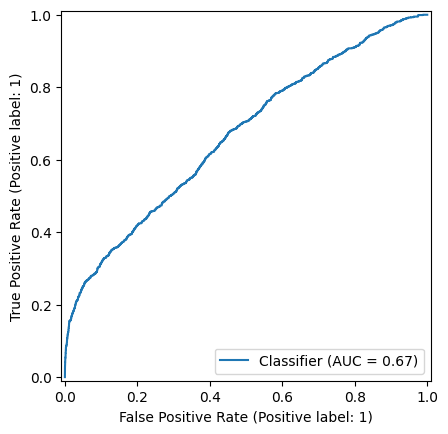

In [26]:
logit_data["prob_1"] = modelo_riesgo_1.predict(logit_data)
logit_data["pred_1"] = (logit_data["prob_1"] >= 0.5).astype(int)

print(classification_report(
    logit_data["late_delivery"].astype(int),
    logit_data["pred_1"]
))

RocCurveDisplay.from_predictions(
    logit_data["late_delivery"].astype(int),
    logit_data["prob_1"]
)

plt.show()


El analista escribe en su informe:

> “El modelo tiene un Accuracy alto, por lo tanto permite detectar correctamente los pedidos que se atrasarán y debería pasar a producción.”


1. identifica qué tipo de modelo utilizó y justificar por qué es o no apropiado para la variable objetivo
2. interpreta correctamente el Odd de la variable `days_to_carrier`
3. evalua la calidad predictiva del modelo utilizando la matriz de confusión, métricas de clasificación y/o curva ROC
4. evalua lo que expuso el analista y determina si es correcto para este problema
5. indica si mantendrías un threshold de `0.5` o si probarías otro valor. No es necesario encontrar un threshold “óptimo”, pero debes justificar tu decisión.

### Tu análisis


In [27]:
# Escribe aquí tu Modelo de Riesgo 2 y evaluación




**Recomendación al equipo:**

Escribe aquí tu conclusión.


---

# Cuarto Bloque (20 puntos)

El equipo de Operaciones necesita anticipar el número de pedidos que recibirá durante los próximos días para planificar su capacidad.

El analista construyó la siguiente serie diaria utilizando los pedidos observados entre enero y julio de 2018


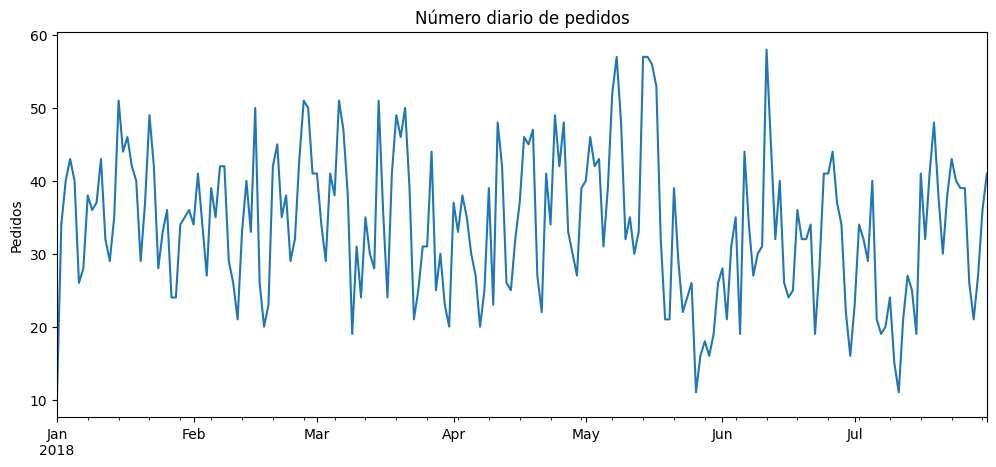

In [28]:
serie_diaria = (
    df
    .dropna(subset=["purchase_date"])
    .groupby("purchase_date")
    .agg(n_orders=("order_id", "nunique"))
    .reset_index()
    .sort_values("purchase_date")
)

serie_diaria = serie_diaria[
    (serie_diaria["purchase_date"] >= "2018-01-01") &
    (serie_diaria["purchase_date"] <= "2018-07-31")
].copy()

serie_diaria.plot(
    x="purchase_date",
    y="n_orders",
    figsize=(12, 5),
    legend=False,
    title="Número diario de pedidos"
)

plt.ylabel("Pedidos")
plt.xlabel("")
plt.show()

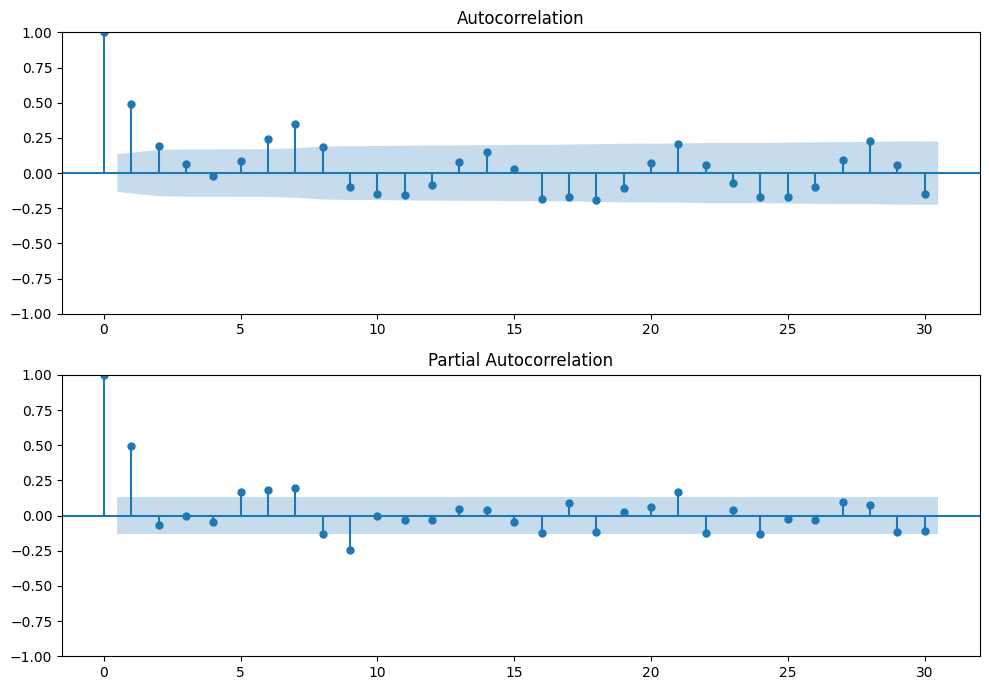

In [29]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

serie = (
    serie_diaria
    .set_index("purchase_date")["n_orders"]
    .asfreq("D")
    .fillna(0)
)

fig, ax = plt.subplots(2, 1, figsize=(10, 7))

plot_acf(serie, lags=30, ax=ax[0])
plot_pacf(serie, lags=30, ax=ax[1])

plt.tight_layout()
plt.show()

Finalmente considera que "test" es la semana que el equipo está pronosticando

In [30]:
train = serie.iloc[:-7]
test = serie.iloc[-7:]

> El analista sostiene que la cantidad de pedidos de un día depende de lo ocurrido en los últimos 7 anteriores, y que bastaría un ARIMA(7,0,7)


1. Utilice ACF y PACF para evaluar si la elección de un ARIMA(7,0,7) está justificada a priori.

2. Ajuste el modelo y evalúe sus diagnósticos. ¿Encuentra evidencia de problemas importantes en los residuos?

3. Compare el pronóstico con los últimos 7 días reales. Considerando conjuntamente ACF/PACF, diagnósticos y capacidad predictiva, ¿apoyaría el trabajo del analista? Justifique.